# Ask the knowledge graph: questions → answers from your local LLM

This notebook answers questions from the graph built in `03_knowlegde_graph.ipynb` (the **v2** files from Part 3), using the same local model and settings as `02_OKF_query.ipynb`. That way the two can be compared fairly.

**Flow:** load facts → NetworkX graph → find the question's entities → walk their edges + search the facts → rank → fetch the source chunks → ask the LLM → answer + sources + timing.

### What is in the graph?

| File | One row = | Fields |
|---|---|---|
| `artifacts/graph_entities_v2.csv` | one **entity** (a node) | `name`, `type` (MODEL, BENCHMARK, METHOD…), `aliases` (other spellings) |
| `artifacts/graph_facts_v2.jsonl` | one **fact** (an edge) | `source --relation--> target`, `support` (how many chunks said it), `evidence` (the quotes), `chunk_ids`, `documents`, `origin` (`v1` or `new`) |
| `data/processed/chunks.jsonl` | one **chunk** of paper text | the text the facts were extracted from, with section and pages |

### How a question is answered

```
question
  │
  ├─► 1. link    find entity names in the question            → seed nodes          "what is it about?"
  ├─► 2. walk    every fact on an edge that touches a seed     → candidate facts     "what does the graph know about them?"
  │     search   BM25 over all facts and their quotes          → more candidates     "facts about words that aren't nodes"
  ├─► 3. rank    BM25 score × how the fact was found (bridge > hop 1 > search > hop 2)
  ├─► 4. chunks  the source chunks behind the top facts, ranked by BM25    "the evidence"
  ├─► 5. pack    facts (with quotes) + chunks, same 18,000-character budget as OKF
  └─► 6. qwen3-4b answers ONLY from that context and cites chunk IDs
```

**How this differs from `02_OKF_query.ipynb`:**

| | OKF bundle | Knowledge graph |
|---|---|---|
| Unit of knowledge | a whole section, or a curated topic page | a fact (`GPT-4 --EVALUATED_ON--> MMLU`) + the chunk it came from |
| Who built the links | written once when the bundle was made (markdown links) | extracted by qwen3-4b from every chunk (~8 hours) |
| Search | BM25 over concepts | entity matching + graph walk + BM25 over facts and chunks |
| The model cites | concept IDs (`topics/calibration`) | chunk IDs (`GPT-4_0036`) |

## 1. Setup

The model and the budget (`NUM_CTX`, `MAX_ANSWER_TOKENS`, `CONTEXT_CHARS`) are **the same as in `02_OKF_query.ipynb`**, so differences in the answers come from retrieval, not from the settings.

Retrieval knobs (step 7):
- `INCLUDE_NEW_FACTS`: use the facts that only Part 3's second check accepted (`origin = new`). Set it to `False` if your grading in section 22 showed they're much worse.
- `HOPS`: 1 = facts touching the seeds, 2 = also facts touching their neighbours.
- `N_FACTS` facts and `N_CHUNKS` chunks go into the context. `N_SEARCH` is how many facts the plain search adds.

In [3]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the project root, wherever Jupyter starts
    os.chdir(Path.cwd().parent)

import ast
import json
import math
import re
import time
from collections import Counter
from pathlib import Path

import networkx as nx
import pandas as pd
import requests

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FACTS_PATH = PROJECT_ROOT / "artifacts" / "graph_facts_v2.jsonl"
ENTITIES_PATH = PROJECT_ROOT / "artifacts" / "graph_entities_v2.csv"
CHUNKS_PATH = PROJECT_ROOT / "data" / "processed" / "chunks.jsonl"

OLLAMA_URL = "http://localhost:11434"
MODEL_NAME = "qwen3:4b-instruct-2507-q4_K_M"     # same as 02_OKF_query.ipynb
NUM_CTX = 8192
MAX_ANSWER_TOKENS = 700
CONTEXT_CHARS = 18000                             # same budget as OKF

# retrieval knobs (step 7)
INCLUDE_NEW_FACTS = True
HOPS = 1
N_FACTS = 20       # facts in the context
N_SEARCH = 10      # facts added by plain search (words that aren't entity names)
N_CHUNKS = 8       # source chunks in the context
PER_PAPER = 3      # max chunks per paper, unless the question names a paper
PAPER_BOOST = 1.5  # facts and chunks from a paper named in the question score 1.5x

for p in (FACTS_PATH, ENTITIES_PATH, CHUNKS_PATH):
    assert p.exists(), f"missing {p} - run 03_knowlegde_graph.ipynb (Part 3) first"
print("project:", PROJECT_ROOT, "| networkx", nx.__version__)

project: c:\Users\Swapn\OneDrive\Documents\GitHub\OKF | networkx 3.6.1


In [4]:
# check: Ollama is running and the model is installed
tags = requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()
installed = [m["name"] for m in tags.get("models", [])]
print("installed:", installed)
assert MODEL_NAME in installed, f"{MODEL_NAME} not installed. Run: ollama pull {MODEL_NAME}"

installed: ['qwen3:4b-instruct-2507-q4_K_M', 'qwen2.5-0.5b-instruct-fc:latest', 'qwen2.5:0.5b-instruct', 'llama3.2:3b', 'qwen3:4b-instruct']


## 2. Load the files

The CSV stores `aliases` and `type_votes` as Python-looking text (`"['HELM']"`), so `ast.literal_eval` turns them back into a list and a dict.

In [5]:
facts = [json.loads(line) for line in FACTS_PATH.open(encoding="utf-8")]
entities = pd.read_csv(ENTITIES_PATH)
entities["aliases"] = entities["aliases"].map(ast.literal_eval)
entities["type_votes"] = entities["type_votes"].map(ast.literal_eval)
with CHUNKS_PATH.open(encoding="utf-8") as f:
    chunk_by_id = {c["chunk_id"]: c for c in (json.loads(line) for line in f if line.strip())}
PAPER_TITLE = {c["document"]: c["title"] for c in chunk_by_id.values()}

print(f"facts: {len(facts)} ({sum(f['origin'] == 'new' for f in facts)} new) | "
      f"entities: {len(entities)} | chunks: {len(chunk_by_id)}")

facts: 2801 (557 new) | entities: 2393 | chunks: 2927


In [6]:
# check: what one fact looks like
print(json.dumps(facts[0], indent=2, ensure_ascii=False)[:1500])

{
  "source": "GPT-4",
  "relation": "OUTPERFORMS",
  "target": "ChatGPT",
  "support": 14,
  "documents": [
    "AGI"
  ],
  "chunk_ids": [
    "AGI_0002",
    "AGI_0006",
    "AGI_0021",
    "AGI_0026",
    "AGI_0027",
    "AGI_0034",
    "AGI_0044",
    "AGI_0050",
    "AGI_0135",
    "AGI_0136",
    "AGI_0146",
    "AGI_0239",
    "AGI_0392",
    "AGI_0396"
  ],
  "evidence": [
    "GPT-4’s performance is strikingly close to human-level performance, and often vastly surpasses prior models such as ChatGPT",
    "We also compare GPT-4’s performance to those of previous LLMs, most notably ChatGPT, which is a fine-tuned version of (an improved) GPT-3",
    "GPT-4 produces impressive outputs that are far superior to those of ChatGPT, a previous state-of-the-art LLM",
    "In Figure 1.7, we give a first example of how much better GPT-4 is at commonsense questions compared to ChatGPT",
    "I would give GPT-4 a slightly higher grade than ChatGPT."
  ],
  "pages": [
    1,
    4,
    7,
  

## 3. Build the graph with NetworkX

NetworkX keeps the whole graph in memory as Python dicts. That's fine for a few thousand nodes; Neo4j only becomes worth it for millions.

We use a **`MultiDiGraph`**:
- **Di** (directed): `GPT-4 --OUTPERFORMS--> ChatGPT` is not the same as the reverse.
- **Multi**: two nodes can have several relations (`GPT-4 OUTPERFORMS ChatGPT` and `GPT-4 COMPARED_WITH ChatGPT`). Each edge gets a `key`, which we set to the relation name.

Every node and edge can carry attributes. Nodes get `type` and `aliases`. Edges get the whole fact plus `fact_id`, its position in the `facts` list.

In [7]:
G = nx.MultiDiGraph()
for e in entities.itertuples():
    G.add_node(e.name, type=e.type, aliases=e.aliases, mentions=e.mentions)
for i, f in enumerate(facts):
    G.add_edge(f["source"], f["target"], key=f["relation"], fact_id=i,
               support=f["support"], documents=f["documents"], origin=f["origin"])

print(f"nodes: {G.number_of_nodes()} | edges: {G.number_of_edges()}")

nodes: 2393 | edges: 2801


In [8]:
# check: the biggest hubs, and how connected the graph is
print("most connected entities (degree = number of facts touching them):")
for name, degree in sorted(G.degree, key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {degree:4}  {name}  ({G.nodes[name]['type']})")

undirected = G.to_undirected(as_view=True)           # direction doesn't matter for "is it connected?"
parts = sorted(nx.connected_components(undirected), key=len, reverse=True)
print(f"\n{len(parts)} separate pieces; the largest has {len(parts[0])} of {G.number_of_nodes()} entities")

most connected entities (degree = number of facts touching them):
   384  GPT-4  (MODEL)
   172  large language model  (MODEL)
   124  foundation model  (CONCEPT)
    61  ChatGPT  (MODEL)
    54  GPT-3  (MODEL)
    52  LLaMA  (MODEL)
    50  accuracy  (METRIC)
    36  chain-of-thought prompting  (METHOD)
    33  OpenAI  (ORGANIZATION)
    32  The Pile  (DATASET)

265 separate pieces; the largest has 1708 of 2393 entities


## 4. Walking the graph

The NetworkX calls this notebook needs:
- `G.out_edges(node, keys=True, data=True)`: the facts where the node is the **source**
- `G.in_edges(node, ...)`: the facts where it's the **target**
- `nx.shortest_path(undirected, a, b)`: the shortest chain of facts linking two entities. This is the **multi-hop** idea: "how is RLHF connected to calibration?" can go through GPT-4.

In [9]:
def show_edges(node, limit=8):
    print(f"{node} ({G.nodes[node]['type']}):")
    for u, v, rel, d in list(G.out_edges(node, keys=True, data=True))[:limit]:
        print(f"   {u} --{rel}--> {v}   (support {d['support']})")
    for u, v, rel, d in list(G.in_edges(node, keys=True, data=True))[:limit]:
        print(f"   {u} --{rel}--> {v}   (support {d['support']})")


show_edges("calibration")

calibration (CONCEPT):
   calibration --MEASURES--> ECE-10   (support 2)
   calibration --MEASURES--> accuracy   (support 2)
   calibration --MEASURES--> classification task   (support 1)
   calibration --MEASURES--> error   (support 1)
   calibration --MEASURES--> expected calibration error   (support 1)
   calibration --MEASURES--> high-stakes settings   (support 1)
   calibration --MEASURES--> selective classification   (support 1)
   calibration --MEASURES--> uncertainty   (support 1)
   expected calibration error --MEASURES--> calibration   (support 2)
   BLOOM --HAS_LIMITATION--> calibration   (support 1)
   GLM --HAS_LIMITATION--> calibration   (support 1)
   GPT-4 --MEASURES--> calibration   (support 1)
   SLiC-HF --USES--> calibration   (support 1)
   selective classification --MEASURES--> calibration   (support 1)


In [10]:
def show_path(a, b):
    path = nx.shortest_path(undirected, a, b)
    print(" -> ".join(path))
    for x, y in zip(path, path[1:]):                 # the fact(s) behind each step
        for u, v, rel in list(G.edges(x, keys=True)) + list(G.in_edges(x, keys=True)):
            if {u, v} == {x, y}:
                print(f"   {u} --{rel}--> {v}")


show_path("reinforcement learning from human feedback", "calibration")

reinforcement learning from human feedback -> GPT-4 -> calibration
   reinforcement learning from human feedback --USES--> GPT-4
   GPT-4 --USES--> reinforcement learning from human feedback
   GPT-4 --MEASURES--> calibration


## 5. Link the question to entities

Find entity names inside the question. Each entity can be written several ways: its `name`, its `aliases` from the CSV, and the short forms in `ALIASES` below. Extraction folded those short forms (`RLHF`, `LLM`…) into the full name, so they aren't in the CSV.

Rules:
- match whole words, case-insensitive, with an optional plural (`language models` → `language model`)
- **longest match wins**: in "large language models", `large language model` beats `language model`

In [11]:
# short forms from 03_knowlegde_graph.ipynb (ALIASES + EXTRA_ALIASES)
ALIASES = {
    "llm": "large language model", "llms": "large language model", "lm": "language model",
    "agi": "artificial general intelligence", "ai": "artificial intelligence",
    "helm": "Holistic Evaluation of Language Models",
    "rlhf": "reinforcement learning from human feedback", "cot": "chain-of-thought prompting",
    "icl": "in-context learning", "sft": "supervised fine-tuning", "peft": "parameter-efficient fine-tuning",
    "rag": "retrieval-augmented generation", "mllm": "multimodal large language model",
    "pii": "personally identifiable information", "nlp": "natural language processing",
}


def tidy(text):
    text = text.replace("“", '"').replace("”", '"').replace("’", "'").replace("‘", "'")
    text = text.replace("--", "-").replace("–", "-").replace("—", "-")
    return re.sub(r"\s+", " ", text).strip().lower()


surface_forms = {}                                   # "rlhf" -> "reinforcement learning from human feedback"
for name, data in G.nodes(data=True):
    for form in [name] + data["aliases"]:
        if len(tidy(form)) >= 2:
            surface_forms.setdefault(tidy(form), name)
for short, name in ALIASES.items():
    if name in G:
        surface_forms.setdefault(short, name)

PATTERNS = [(re.compile(r"(?<![a-z0-9])" + re.escape(form) + r"(?:s|es)?(?![a-z0-9])"), name)
            for form, name in surface_forms.items()]


def link(question):
    q = tidy(question)
    spans = [(m.start(), m.end(), name) for rx, name in PATTERNS for m in rx.finditer(q)]
    spans.sort(key=lambda s: (s[0] - s[1], s[0]))   # longest first
    taken, seeds = [], []
    for start, end, name in spans:
        if any(start < t_end and t_start < end for t_start, t_end in taken):
            continue                                 # overlaps a longer match
        taken.append((start, end))
        if name not in seeds:
            seeds.append(name)
    return seeds


print(f"{len(surface_forms)} surface forms")
for q in ["How does HELM measure calibration of language models?",
          "What are the three steps of RLHF, and how did RLHF affect GPT-4's calibration?",
          "How did the Sparks of AGI paper test GPT-4 on theory of mind?"]:
    print(f"{q}\n   -> {link(q)}")

2726 surface forms
How does HELM measure calibration of language models?
   -> ['language model', 'calibration', 'Holistic Evaluation of Language Models']
What are the three steps of RLHF, and how did RLHF affect GPT-4's calibration?
   -> ['calibration', 'GPT-4', 'reinforcement learning from human feedback']
How did the Sparks of AGI paper test GPT-4 on theory of mind?
   -> ['GPT-4', 'artificial general intelligence']


Look at the last one. **Theory of mind is not a node**: no accepted fact had it as source or target (the "0 facts" from Part 3's topic check). A walk that starts only from `GPT-4` would get GPT-4's ~380 facts and nothing about theory of mind. That's why step 7 also *searches* the facts.

## 6. Search: BM25 over facts and chunks

Same BM25 as in `02_OKF_query.ipynb`, just over different "documents":
- **facts**: `source relation target` plus the evidence quotes. The quotes are the key part: they contain words that never became entities ("theory of mind", "Sally-Anne").
- **chunks**: the paper text. Used only to *order* the chunks the graph already picked (step 7), never to find new ones.

In [12]:
STOPWORDS = set('''a an the of and or to in on for with by from at as is are was were be been being it its this that these
those what which who whom how why when where do does did can could should would will may might about into than then
there their they them we our you your i me my he she his her not no yes vs'''.split())


def tokenize(text):
    return [t for t in re.findall(r"[a-z0-9]+(?:[-.][a-z0-9]+)*", text.lower()) if t not in STOPWORDS]


class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):           # docs: {id: text}
        self.k1, self.b = k1, b
        self.tf = {key: Counter(tokenize(text)) for key, text in docs.items()}
        self.length = {key: sum(tf.values()) for key, tf in self.tf.items()}
        self.avg_len = sum(self.length.values()) / len(self.length)
        df = Counter(word for tf in self.tf.values() for word in tf)
        n = len(self.tf)
        self.idf = {w: math.log(1 + (n - d + 0.5) / (d + 0.5)) for w, d in df.items()}

    def scores(self, query, keys=None):                 # keys: only score these documents
        q = tokenize(query)
        result = {}
        for key in (self.tf if keys is None else keys):
            tf = self.tf[key]
            norm = 1 - self.b + self.b * self.length[key] / self.avg_len
            s = sum(self.idf[w] * tf[w] * (self.k1 + 1) / (tf[w] + self.k1 * norm) for w in q if w in tf)
            if s > 0:
                result[key] = s
        return result


def fact_text(f):
    return f"{f['source']} {f['relation'].replace('_', ' ').lower()} {f['target']}. " + " ".join(f["evidence"])


start = time.perf_counter()
fact_index = BM25({i: fact_text(f) for i, f in enumerate(facts)})
chunk_index = BM25({cid: c["text"] for cid, c in chunk_by_id.items()})
print(f"indexed {len(facts)} facts and {len(chunk_by_id)} chunks in {(time.perf_counter() - start) * 1000:.0f} ms")

indexed 2801 facts and 2927 chunks in 985 ms


In [13]:
# check: plain fact search finds theory of mind through a quote
s = fact_index.scores("theory of mind test GPT-4 Sparks of AGI")
for i in sorted(s, key=s.get, reverse=True)[:5]:
    f = facts[i]
    print(f"{s[i]:5.1f}  {f['source']} --{f['relation']}--> {f['target']}  {f['chunk_ids']}")

 21.5  Sally-Anne test --IS_A--> false-belief test  ['AGI_0217']
 13.5  GPT-4 --HAS_CAPABILITY--> graph theory  ['AGI_0167']
 11.1  GPT-4 --HAS_CAPABILITY--> algorithm  ['AGI_0167']
 10.8  GPT-4 --HAS_RISK--> artificial general intelligence  ['LLMs_0015']
  9.8  GPT-4 --IS_A--> artificial general intelligence  ['AGI_0002']


## 7. Retrieve: walk + search → rank facts → pick chunks

**1. Collect candidate facts.** Each one is tagged with how it was found:

| channel | meaning | weight |
|---|---|---|
| `bridge` | both ends are entities from the question, e.g. `GPT-4 --MEASURES--> calibration` | 2.0 |
| `hop 1` | one end is an entity from the question | 1.0 |
| `search` | one of the `N_SEARCH` best BM25 facts overall | 0.7 |
| `hop 2` | touches a neighbour of a question entity (only with `HOPS = 2`) | 0.5 |

**2. Rank.** Fact score = BM25(question, fact) × weight. If the question names a paper ("the GPT-4 technical report", "HELM", "Sparks of AGI"), facts from that paper score `PAPER_BOOST`×. We keep the top `N_FACTS`.

**3. Pick chunks.** The candidates are the chunks the top facts came from (`chunk_ids`). They're ordered by BM25 against the question. Then:
- If no paper is named, take at most `PER_PAPER` chunks per paper, so "which papers…" questions see several papers.
- If a paper is named, stay in it.

The graph decides **which** chunks are allowed. BM25 only decides their **order**. That's what makes this graph retrieval and not plain chunk search.

In [14]:
PAPER_HINTS = {
    "AGI": ["sparks of agi", "sparks of artificial general intelligence", "sparks paper"],
    "GPT-4": ["gpt-4 technical report", "gpt-4 report", "technical report", "system card"],
    "Holistic_Eval": ["helm", "holistic evaluation of language models"],
    "Foundation_Models": ["foundation models report", "opportunities and risks of foundation models"],
    "LLMs": ["llm survey", "survey of large language models"],
}
WEIGHT = {"bridge": 2.0, "hop 1": 1.0, "search": 0.7, "hop 2": 0.5}


def papers_named(question):
    q = tidy(question)
    return [doc for doc, hints in PAPER_HINTS.items()
            if any(re.search(r"(?<![a-z0-9])" + re.escape(h) + r"(?![a-z0-9])", q) for h in hints)]


def retrieve(question, hops=None, n_facts=None, n_search=None, n_chunks=None, include_new=None):
    hops = HOPS if hops is None else hops
    n_facts = N_FACTS if n_facts is None else n_facts
    n_search = N_SEARCH if n_search is None else n_search
    n_chunks = N_CHUNKS if n_chunks is None else n_chunks
    include_new = INCLUDE_NEW_FACTS if include_new is None else include_new
    allowed = lambda i: include_new or facts[i]["origin"] == "v1"

    seeds, papers = link(question), papers_named(question)

    # 1) candidates: walk out from the seeds ...
    channel = {}                                   # fact_id -> how it was found
    frontier, visited = set(seeds), set(seeds)
    for hop in range(1, hops + 1):
        next_frontier = set()
        for node in frontier:
            for u, v, rel, d in list(G.out_edges(node, keys=True, data=True)) + list(G.in_edges(node, keys=True, data=True)):
                if allowed(d["fact_id"]) and d["fact_id"] not in channel:
                    channel[d["fact_id"]] = "bridge" if (u in seeds and v in seeds) else f"hop {hop}"
                next_frontier |= {u, v} - visited
        visited |= next_frontier
        frontier = next_frontier
    # ... plus the best facts from plain search
    bm25 = fact_index.scores(question)
    added = 0
    for i in sorted(bm25, key=bm25.get, reverse=True):
        if added == n_search:
            break
        if allowed(i) and i not in channel:
            channel[i] = "search"
            added += 1

    # 2) rank facts
    def fact_score(i):
        s = bm25.get(i, 0) * WEIGHT[channel[i]]
        if papers and set(facts[i]["documents"]) & set(papers):
            s *= PAPER_BOOST
        return s

    top = sorted((i for i in channel if bm25.get(i, 0) > 0), key=fact_score, reverse=True)[:n_facts]

    # 3) chunks behind the top facts, ordered by BM25 (+ paper boost), at most PER_PAPER per paper
    votes = Counter(cid for i in top for cid in facts[i]["chunk_ids"] if cid in chunk_by_id)
    chunk_bm25 = chunk_index.scores(question, list(votes))

    def chunk_score(cid):
        s = chunk_bm25.get(cid, 0)
        if papers and chunk_by_id[cid]["document"] in papers:
            s *= PAPER_BOOST
        return s

    picked, per_paper = [], Counter()
    for cid in sorted(votes, key=lambda c: (chunk_score(c), votes[c]), reverse=True):
        doc = chunk_by_id[cid]["document"]
        if not papers and per_paper[doc] >= PER_PAPER:
            continue
        picked.append(cid)
        per_paper[doc] += 1
        if len(picked) == n_chunks:
            break

    return {"seeds": seeds, "papers": papers,
            "facts": [(i, channel[i], round(fact_score(i), 1)) for i in top],
            "chunks": [(cid, votes[cid], round(chunk_score(cid), 1)) for cid in picked]}


r = retrieve("How did the Sparks of AGI paper test GPT-4 on theory of mind?")
print("seeds:", r["seeds"], "| paper named:", r["papers"])
for i, how, score in r["facts"][:8]:
    f = facts[i]
    print(f"   {how:7} {score:5.1f}  {f['source']} --{f['relation']}--> {f['target']}")
print("chunks:", [cid for cid, _, _ in r["chunks"]])

seeds: ['GPT-4', 'artificial general intelligence'] | paper named: ['AGI']
   bridge   29.3  GPT-4 --IS_A--> artificial general intelligence
   search   22.6  Sally-Anne test --IS_A--> false-belief test
   bridge   21.6  GPT-4 --HAS_RISK--> artificial general intelligence
   hop 1    20.2  GPT-4 --HAS_CAPABILITY--> graph theory
   hop 1    16.7  GPT-4 --HAS_CAPABILITY--> algorithm
   hop 1    12.0  GPT-4 --HAS_LIMITATION--> deep understanding
   hop 1    11.1  GPT-4 --EVALUATED_ON--> Multistate Bar Exam
   hop 1    10.9  GPT-4 --HAS_CAPABILITY--> Multistate Bar Exam
chunks: ['AGI_0217', 'AGI_0027', 'AGI_0002', 'LLMs_0015', 'AGI_0024', 'AGI_0167', 'AGI_0028', 'AGI_0076']


## 8. Build the context

Two parts, in this order:
1. **Facts**: one line per fact, with its first quote and up to 3 chunk IDs. They act like a map of what's related.
2. **Source passages**: the chunks, each with a header `### [chunk-id]` plus paper, section and pages. This is where the numbers and explanations are; the graph itself stores none.

Blocks are added until `CONTEXT_CHARS` is used up, the same as OKF.

In [15]:
def chunk_header(cid):
    c = chunk_by_id[cid]
    pages = f"p. {c['page_start']}" if c["page_start"] == c["page_end"] else f"pp. {c['page_start']}-{c['page_end']}"
    return f"{PAPER_TITLE[c['document']]} > {' > '.join(c['section_path'])}, {pages}"


def render_fact(i):
    f = facts[i]
    quote = f["evidence"][0][:220] if f["evidence"] else ""
    cites = ", ".join(f["chunk_ids"][:3])
    return (f"- {f['source']} --{f['relation']}--> {f['target']} "
            f"(found in {f['support']} chunk(s)) [{cites}]\n  quote: \"{quote}\"")


def build_context(result, budget=CONTEXT_CHARS):
    fact_lines, size = [], 0
    for i, _, _ in result["facts"]:
        line = render_fact(i)
        if size + len(line) > budget:
            break
        fact_lines.append(line)
        size += len(line)
    used_facts = result["facts"][:len(fact_lines)]

    passages = []
    for cid, _, _ in result["chunks"]:
        block = f"### [{cid}] ({chunk_header(cid)})\n{chunk_by_id[cid]['text'].strip()}"
        if size + len(block) > budget:
            continue                                   # skip what doesn't fit; a smaller one may still fit
        passages.append((cid, block))
        size += len(block)

    context = ("## Facts from the knowledge graph\n" + "\n".join(fact_lines)
               + "\n\n## Source passages\n\n" + "\n\n".join(block for _, block in passages))
    cited_ids = {cid for i, _, _ in used_facts for cid in facts[i]["chunk_ids"][:3]} | {cid for cid, _ in passages}
    return context, [cid for cid, _ in passages], cited_ids


context, passage_ids, _ = build_context(retrieve("How did the Sparks of AGI paper test GPT-4 on theory of mind?"))
print(f"{len(passage_ids)} passages, {len(context)} chars (~{len(context) // 4} tokens)\n")
print(context[:2000])

8 passages, 13657 chars (~3414 tokens)

## Facts from the knowledge graph
- GPT-4 --IS_A--> artificial general intelligence (found in 1 chunk(s)) [AGI_0002]
  quote: "we believe that it could reasonably be viewed as an early (yet still incomplete) version of an artificial general intelligence (AGI) system"
- Sally-Anne test --IS_A--> false-belief test (found in 1 chunk(s)) [AGI_0217]
  quote: "We start with a modernized version of the Sally-Anne test [BCLF85], a classic false-belief test that is widely used to assess theory of mind in children."
- GPT-4 --HAS_RISK--> artificial general intelligence (found in 1 chunk(s)) [LLMs_0015]
  quote: "the advent of ChatGPT and GPT-4 leads to the rethinking of the possibilities of artificial general intelligence (AGI)"
- GPT-4 --HAS_CAPABILITY--> graph theory (found in 1 chunk(s)) [AGI_0167]
  quote: "GPT-4 demonstrates understanding of the concepts from graph theory and algorithms."
- GPT-4 --HAS_CAPABILITY--> algorithm (found in 1 chunk(s)) [AG

## 9. Ask the local LLM

Same call and the same strictness as `02_OKF_query.ipynb`. Two differences in the prompt:
- the model cites **chunk IDs**
- it's warned that facts were extracted automatically, so when a fact and a passage disagree, the **passage wins**

In [16]:
SYSTEM_PROMPT = '''You answer questions about five AI research papers using ONLY the knowledge below.
The knowledge has two parts: facts from a knowledge graph (source --RELATION--> target, with a quote and the chunk ids it came from),
and source passages, each starting with ### [chunk-id]. Rules:
- Use only what the facts and passages state. Do not add outside knowledge.
- The facts were extracted automatically and can be vague or wrong. If a fact and a passage disagree, trust the passage.
- After each claim, cite the chunk id(s) you used in square brackets, e.g. [GPT-4_0036].
- Keep numbers, model names and percentages exactly as written.
- If the knowledge does not contain the answer, say: "The graph does not contain this." and stop.
- Be concise: a short paragraph or a few bullets.'''


def ask_llm(question, context):
    start = time.perf_counter()
    response = requests.post(
        f"{OLLAMA_URL}/api/chat",
        json={
            "model": MODEL_NAME,
            "stream": False,
            "options": {"temperature": 0, "num_ctx": NUM_CTX, "num_predict": MAX_ANSWER_TOKENS},
            "messages": [
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": f"Knowledge:\n\n{context}\n\n---\n\nQuestion: {question}"},
            ],
        },
        timeout=600,
    )
    response.raise_for_status()
    data = response.json()
    answer = re.sub(r"<think>.*?</think>", "", data["message"]["content"], flags=re.S).strip()
    stats = {
        "prompt_tokens": data.get("prompt_eval_count"),
        "answer_tokens": data.get("eval_count"),
        "generation_ms": round((time.perf_counter() - start) * 1000, 1),     # wall-clock time of the LLM call
    }
    return answer, stats

In [17]:
# warm-up: the first call loads the model into GPU memory (slow); later calls are much faster
start = time.perf_counter()
_ = ask_llm("Say OK.", "### [warmup]\nOK")
print(f"warm-up took {time.perf_counter() - start:.1f}s")

warm-up took 11.7s


## 10. Put it together: `ask()`

Prints:
- the **seeds** (entities found in the question) and any paper it names
- the **facts** used, with how each was found and its score
- the **chunks** used, with how many top facts pointed to each
- the **answer**, and the **sources** it cited (chunk → paper, section, pages)
- **timing**: retrieval and generation in ms, tokens

It returns the same keys as `ask()` in `02_OKF_query.ipynb`, so the two can be put in one table later.

In [18]:
def sources_for(answer, cited_ids):
    return [f"{cid}  ->  {chunk_header(cid)}" for cid in sorted(cited_ids) if cid in answer]


def context_items(context):
    """The context as a list of blocks, in order (for DeepEval): all facts as one block, then one block per passage."""
    facts_part, _, passages_part = context.partition("\n\n## Source passages\n\n")
    return [facts_part] + [p for p in re.split(r"\n\n(?=### \[)", passages_part) if p.strip()]


def ask(question, show_context=False, draw=False, **retrieve_kwargs):
    t0 = time.perf_counter()
    result = retrieve(question, **retrieve_kwargs)
    context, passage_ids, cited_ids = build_context(result)
    retrieval_ms = (time.perf_counter() - t0) * 1000

    answer, stats = ask_llm(question, context)

    print(f"Q: {question}\n")
    print(f"seeds: {result['seeds'] or '(none found)'}" + (f" | paper named: {result['papers']}" if result["papers"] else ""))
    print(f"facts ({len(result['facts'])}, top 10 shown):")
    for i, how, score in result["facts"][:10]:
        f = facts[i]
        print(f"   {how:7} {score:5.1f}  {f['source']} --{f['relation']}--> {f['target']}"
              + ("   [new]" if f["origin"] == "new" else ""))
    print("chunks:")
    for cid, votes, score in result["chunks"]:
        print(f"   {score:5.1f}  {cid:22} {votes} fact(s)  {' > '.join(chunk_by_id[cid]['section_path'])[:60]}"
              + ("" if cid in passage_ids else "   (did not fit)"))
    if show_context:
        print("\n--- context sent to the model ---\n" + context + "\n--- end context ---")
    print("\nanswer:\n" + answer)
    print("\nsources cited:")
    for line in sources_for(answer, cited_ids) or ["(none - check the answer!)"]:
        print("   " + line)
    print(f"\ntiming: retrieval {retrieval_ms:.0f} ms | generation {stats['generation_ms']:.0f} ms | "
          f"tokens in/out {stats['prompt_tokens']}/{stats['answer_tokens']} | context {len(context)} chars")
    if draw:
        draw_retrieved(result)
    return {"question": question, "answer": answer, "retrieved": result, "used": passage_ids,
            "retrieval_context": context_items(context),           # the exact blocks the model saw (for DeepEval)
            "retrieval_ms": round(retrieval_ms, 1), **stats}

## 11. See what the graph retrieved

`draw_retrieved()` draws the facts a question used: **orange** = entities from the question, **blue** = everything they led to. Use it as `ask(q, draw=True)`. Needs `matplotlib`.

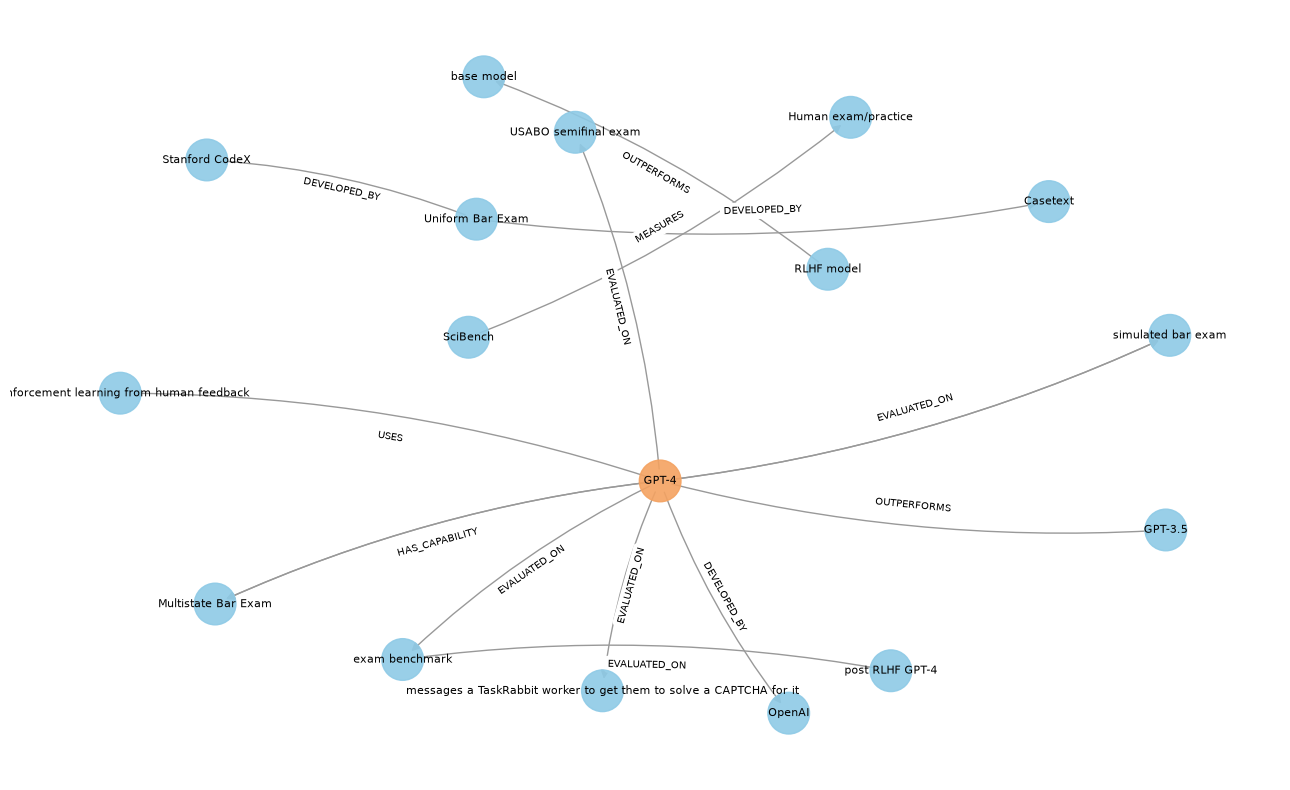

In [19]:
def draw_retrieved(result, max_facts=15):
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("pip install matplotlib to draw the graph")
        return
    sub = nx.MultiDiGraph()
    for i, _, _ in result["facts"][:max_facts]:
        f = facts[i]
        sub.add_edge(f["source"], f["target"], key=f["relation"])
    if not sub:
        print("no facts to draw")
        return
    pos = nx.spring_layout(sub, seed=42, k=1.2)
    colors = ["#f4a261" if n in result["seeds"] else "#8ecae6" for n in sub.nodes]
    plt.figure(figsize=(13, 8))
    nx.draw_networkx_nodes(sub, pos, node_color=colors, node_size=900, alpha=0.9)
    nx.draw_networkx_labels(sub, pos, font_size=8)
    nx.draw_networkx_edges(sub, pos, arrows=True, arrowsize=12, edge_color="#999999", connectionstyle="arc3,rad=0.08")
    labels = {(u, v): rel for u, v, rel in sub.edges(keys=True)}
    nx.draw_networkx_edge_labels(sub, pos, edge_labels=labels, font_size=7)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


draw_retrieved(retrieve("What score did GPT-4 get on the bar exam?"))

## 12. Try it

The same seven questions as `02_OKF_query.ipynb`, in the same order, so you can put the answers side by side.

In [20]:
r1 = ask("How does HELM measure calibration of language models?")

Q: How does HELM measure calibration of language models?

seeds: ['language model', 'calibration', 'Holistic Evaluation of Language Models'] | paper named: ['Holistic_Eval']
facts (20, top 10 shown):
   hop 1    21.1  calibration --MEASURES--> classification task
   hop 1    21.1  calibration --MEASURES--> selective classification
   hop 1    17.1  Holistic Evaluation of Language Models --MEASURES--> transparency   [new]
   hop 1    15.6  Holistic Evaluation of Language Models --COVERS--> Reddit
   hop 1    15.6  Holistic Evaluation of Language Models --COVERS--> Swahili
   hop 1    15.6  Holistic Evaluation of Language Models --COVERS--> elderly
   hop 1    15.6  Holistic Evaluation of Language Models --COVERS--> internet
   hop 1    15.4  calibration --MEASURES--> ECE-10
   search   15.1  calibration error --MEASURES--> ECE-10
   hop 1    14.8  calibration --PART_OF--> natural language processing
chunks:
    18.2  Holistic_Eval_0238     1 fact(s)  8 Experiments and results > 8.1 Meta

In [21]:
r2 = ask("What did the GPT-4 technical report say about predictable scaling?")

Q: What did the GPT-4 technical report say about predictable scaling?

seeds: ['predictable scaling', 'technical report', 'GPT-4'] | paper named: ['GPT-4']
facts (20, top 10 shown):
   bridge   37.7  GPT-4 --USES--> predictable scaling
   hop 1    25.8  GPT-4 --USES--> scaling
   hop 1    18.5  GPT-4 --EVALUATED_ON--> OpenAI technical report on GPT-4
   hop 1    17.5  predictable scaling --BUILDS_ON--> deep learning stack
   hop 1    16.8  technical report --DEVELOPED_BY--> OpenAI
   hop 1    16.1  GPT-4 --IS_A--> large multimodal model
   hop 1    14.7  GPT-4 --HAS_RISK--> truthfulness
   hop 1    14.2  GPT-4 --HAS_CAPABILITY--> capability
   hop 1    14.1  predictable scaling --BUILDS_ON--> large language model
   hop 1    13.8  GPT-4 --HAS_LIMITATION--> architecture
chunks:
    18.6  GPT-4_0048             2 fact(s)  7 Conclusion
    15.5  LLMs_0068              1 fact(s)  2 OVERVIEW > 2.2 Technical Evolution of GPT-series Models
    13.9  GPT-4_0008             1 fact(s)  2 Scope a

In [22]:
r3 = ask("What is homogenization in foundation models and why is it risky?")

Q: What is homogenization in foundation models and why is it risky?

seeds: ['foundation model', 'homogenization']
facts (20, top 10 shown):
   hop 1    11.1  homogenization --IS_A--> emergence
   hop 1     9.5  BERT --HAS_LIMITATION--> homogenization
   hop 1     9.3  homogenization --PART_OF--> AI research
   hop 1     7.6  multilingual foundation models --BUILDS_ON--> foundation model
   hop 1     7.3  foundation model --IS_A--> general-purpose technology
   hop 1     7.2  foundation model --IS_A--> task-agnostic
   hop 1     7.2  foundation model --PART_OF--> biomedicine
   hop 1     7.2  foundation model --PART_OF--> healthcare
   hop 1     7.2  intermediary assets --IS_A--> foundation model
   hop 1     7.1  interpretability --MEASURES--> foundation model
chunks:
    17.7  Foundation_Models_0019 1 fact(s)  1 INTRODUCTION > 1.1 Emergence and homogenization
    11.9  Foundation_Models_0006 1 fact(s)  1 INTRODUCTION > 1.1 Emergence and homogenization
     8.5  Foundation_Models_0558

Q: How did the Sparks of AGI paper test GPT-4 on theory of mind?

seeds: ['GPT-4', 'artificial general intelligence'] | paper named: ['AGI']
facts (20, top 10 shown):
   bridge   29.3  GPT-4 --IS_A--> artificial general intelligence
   search   22.6  Sally-Anne test --IS_A--> false-belief test   [new]
   bridge   21.6  GPT-4 --HAS_RISK--> artificial general intelligence
   hop 1    20.2  GPT-4 --HAS_CAPABILITY--> graph theory
   hop 1    16.7  GPT-4 --HAS_CAPABILITY--> algorithm
   hop 1    12.0  GPT-4 --HAS_LIMITATION--> deep understanding   [new]
   hop 1    11.1  GPT-4 --EVALUATED_ON--> Multistate Bar Exam
   hop 1    10.9  GPT-4 --HAS_CAPABILITY--> Multistate Bar Exam
   hop 1    10.1  GPT-4 --EVALUATED_ON--> HumanEval
   hop 1     9.9  GPT-4 --EVALUATED_ON--> LeetCode's Interview Assessment platform
chunks:
    35.0  AGI_0217               1 fact(s)  6.1 Understanding Humans: Theory of Mind > 6.1.1 Testing spe
    24.4  AGI_0027               1 fact(s)  1 Introduction > 1.2 Organi

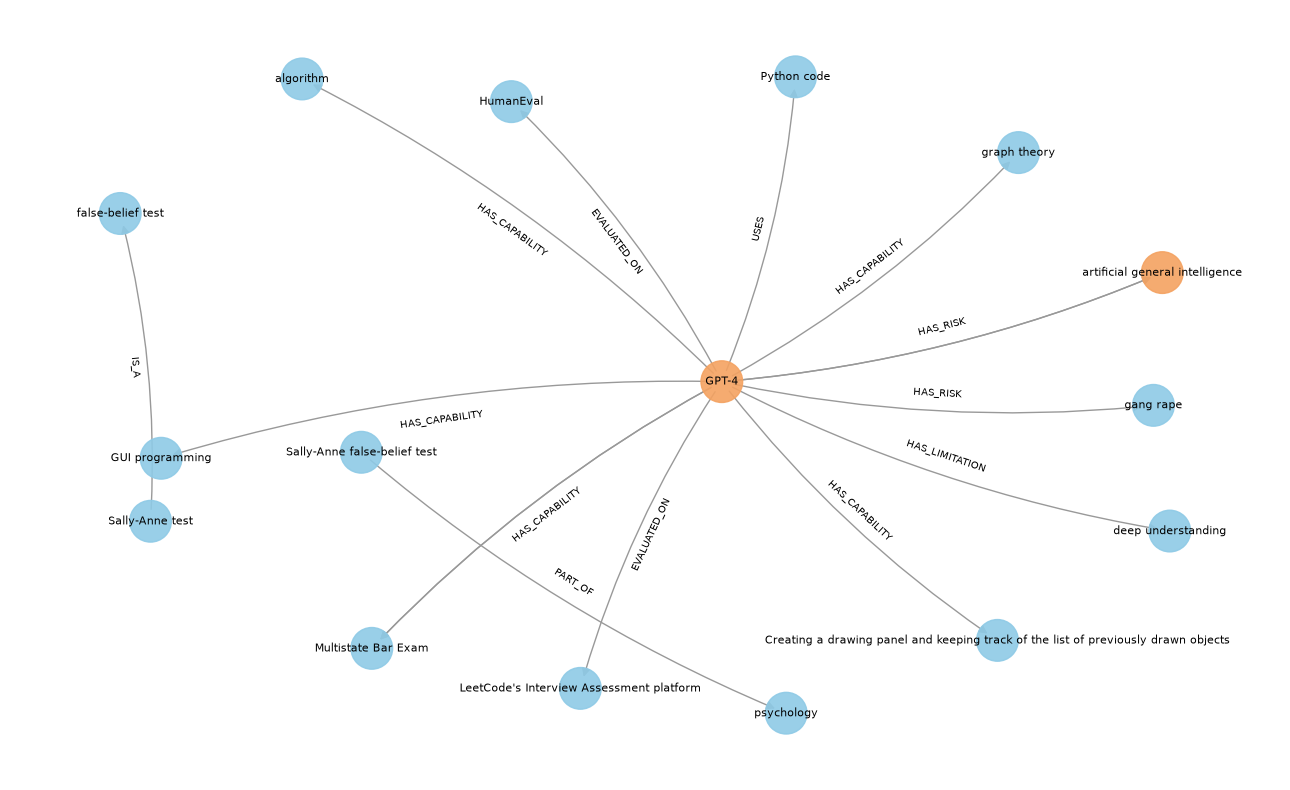

In [23]:
r4 = ask("How did the Sparks of AGI paper test GPT-4 on theory of mind?", draw=True)

Two questions that need **several papers at once**. OKF has curated pages that already combine the papers. Here, the per-paper limit on chunks has to do that work:

In [24]:
r5 = ask("Which papers discuss hallucination, and what does each one say about it?")

Q: Which papers discuss hallucination, and what does each one say about it?

seeds: ['hallucination']
facts (20, top 10 shown):
   hop 1     6.9  extrinsic hallucination --IS_A--> hallucination
   hop 1     6.9  intrinsic hallucination --IS_A--> hallucination
   hop 1     6.4  factual hallucination --IS_A--> hallucination
   hop 1     6.1  large language model --HAS_LIMITATION--> hallucination
   hop 1     6.1  large language model --HAS_RISK--> hallucination
   hop 1     5.8  uncertainty estimation --USES--> hallucination
   hop 1     5.8  uncertainty-based methods --HAS_RISK--> hallucination
   search    5.7  TruthfulQA --MEASURES--> hallucination detection
   hop 1     5.7  knowledge faithfulness score --MEASURES--> hallucination
   hop 1     5.4  ChatGPT --HAS_LIMITATION--> hallucination
chunks:
     9.1  LLMs_0438              1 fact(s)  7 CAPACITY AND EVALUATION > 7.1 Basic Ability > 7.1.2 Knowle
     8.8  LLMs_0682              1 fact(s)  9 ADVANCED TOPICS > 9.7 Hallucination
  

In [25]:
r6 = ask("What are the three steps of RLHF, and how did RLHF affect GPT-4's calibration?")

Q: What are the three steps of RLHF, and how did RLHF affect GPT-4's calibration?

seeds: ['calibration', 'GPT-4', 'reinforcement learning from human feedback']
facts (20, top 10 shown):
   bridge   40.6  GPT-4 --USES--> reinforcement learning from human feedback
   bridge   22.3  reinforcement learning from human feedback --USES--> GPT-4
   bridge   21.5  GPT-4 --MEASURES--> calibration
   hop 1    12.4  GPT-4 --USES--> zero-shot prompting
   hop 1    12.2  GPT-4 --OUTPERFORMS--> incorrect behavior
   hop 1    12.1  GPT-4 --EVALUATED_ON--> exam benchmark
   hop 1    11.9  GPT-4 --OUTPERFORMS--> incorrect behavior rate
   hop 1    11.0  GPT-4 --USES--> few-shot prompting
   hop 1    10.7  GPT-4 --HAS_RISK--> Disallowed Prompt
   search   10.5  post RLHF GPT-4 --EVALUATED_ON--> exam benchmark   [new]
chunks:
    20.1  GPT-4_0036             1 fact(s)  5 Limitations
    17.1  GPT-4_0086             3 fact(s)  B Impact of RLHF on capability
    15.9  GPT-4_0042             2 fact(s)  6 Ri

And one the graph **can't** answer. It should say so instead of inventing an answer:

In [26]:
r7 = ask("How many parameters does Gemini Ultra have?")

Q: How many parameters does Gemini Ultra have?

seeds: (none found)
facts (10, top 10 shown):
   search    7.5  T0++ --OUTPERFORMS--> Anthropic-LM v4-s3
   search    6.0  GPT-3 --HAS_CAPABILITY--> natural language
   search    5.1  perplexity --MEASURES--> downstream use case
   search    5.1  fine-tuning --USES--> memory
   search    4.9  GPT-4 --HAS_CAPABILITY--> proof that there are infinitely many primes
   search    4.9  foundation model --IS_A--> many models
   search    4.8  language model --USES--> decoding parameters
   search    4.2  decoding --USES--> max tokens
   search    4.1  ChatGPT --EVALUATED_ON--> write a proof of the fact that there are infinitely many primes
   search    4.1  GPT-4 --EVALUATED_ON--> write a proof of the fact that there are infinitely many primes
chunks:
    10.5  Foundation_Models_0360 1 fact(s)  4 TECHNOLOGY > 4.3 Adaptation > 4.3.1 Methods for foundation
     7.0  Holistic_Eval_0260     1 fact(s)  8 Experiments and results > 8.1 Meta-analysis
   

In [27]:
# summary of the seven runs
summary = pd.DataFrame([{k: r[k] for k in ("question", "retrieval_ms", "generation_ms", "prompt_tokens", "answer_tokens")}
                        for r in (r1, r2, r3, r4, r5, r6, r7)])
summary["question"] = summary["question"].str[:60]
display(summary)

,question,retrieval_ms,generation_ms,prompt_tokens,answer_tokens
0,How does HELM measure calibration of language ...,47.6,7922.5,3431,204
1,What did the GPT-4 technical report say about ...,40.7,6115.0,3233,109
2,What is homogenization in foundation models an...,36.9,7744.1,2293,212
3,How did the Sparks of AGI paper test GPT-4 on ...,38.6,6363.5,3716,114
4,"Which papers discuss hallucination, and what d...",42.7,15390.7,3337,557
5,"What are the three steps of RLHF, and how did ...",37.0,8238.4,3492,211
6,How many parameters does Gemini Ultra have?,28.3,3946.4,2858,8


## 13. Your turn

Q: Which model was most accurate on TruthfulQA in HELM?

seeds: ['TruthfulQA', 'Holistic Evaluation of Language Models'] | paper named: ['Holistic_Eval']
facts (20, top 10 shown):
   search   13.1  text-davinci-002 --HAS_CAPABILITY--> question answering
   hop 1    11.1  TruthfulQA --PART_OF--> language modeling
   search   10.9  text-davinci-002 --HAS_LIMITATION--> morphology
   search   10.9  text-davinci-002 --HAS_LIMITATION--> semantic
   search   10.5  T0++ --OUTPERFORMS--> TNLG v2
   hop 1    10.5  multiple choice (joint) --USES--> TruthfulQA   [new]
   search   10.1  GLM --HAS_LIMITATION--> calibration   [new]
   hop 1    10.0  TruthfulQA --COVERS--> biology
   hop 1    10.0  TruthfulQA --COVERS--> law
   hop 1     9.9  TruthfulQA --COVERS--> diverse styles
chunks:
    21.2  Holistic_Eval_0309     2 fact(s)  8 Experiments and results > 8.4 Targeted evaluations
    18.0  Holistic_Eval_0254     1 fact(s)  8 Experiments and results > 8.1 Meta-analysis
    17.9  Holistic_Eval_0038  

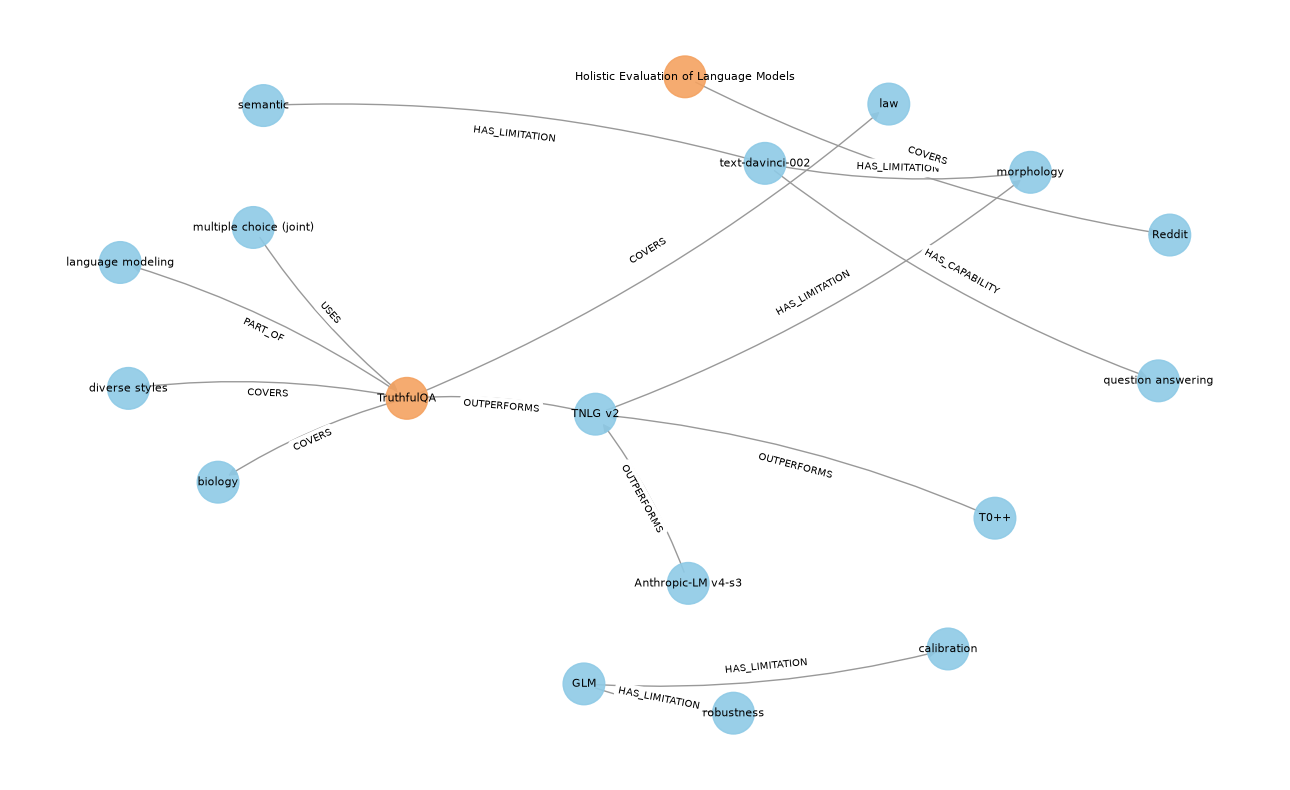

In [28]:
question = "Which model was most accurate on TruthfulQA in HELM?"
result = ask(question, show_context=False, draw=True)

## Save results for the comparison

This runs every question in `data/eval/eval_questions.jsonl` through `ask()` (quietly) and saves one line per question to `artifacts/results/graph.jsonl`. Each line holds:
- the **answer**
- **`retrieval_context`**: the exact blocks the model saw, in order
- **timing**: `retrieval_ms`, `generation_ms`
- **tokens**: `prompt_tokens`, `answer_tokens`

`08_evaluate_methods.ipynb` grades all four methods from these files with DeepEval, using one judge, so every method is judged the same way. Re-run this cell whenever you change the method or the questions.

In [29]:
import contextlib
import io

METHOD = "graph"
EVAL_PATH = PROJECT_ROOT / "data" / "eval" / "eval_questions.jsonl"
RESULTS_PATH = PROJECT_ROOT / "artifacts" / "results" / f"{METHOD}.jsonl"
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

eval_questions = [json.loads(line) for line in EVAL_PATH.open(encoding="utf-8") if line.strip()]
print(f"{len(eval_questions)} questions -> {RESULTS_PATH}")


def ask_quietly(question, attempts=2):
    # one retry, in case Ollama or Qdrant hiccups
    for attempt in range(attempts):
        try:
            with contextlib.redirect_stdout(io.StringIO()):          # ask() prints a lot; keep this cell readable
                return ask(question)
        except Exception as exc:
            if attempt == attempts - 1:
                raise
            print(f"   failed ({type(exc).__name__}: {str(exc)[:80]}), retrying in 10 s")
            time.sleep(10)


# written line by line: if it stops halfway, the answers so far are kept (08 shows the rest as missing)
with RESULTS_PATH.open("w", encoding="utf-8") as f:
    for n, item in enumerate(eval_questions, start=1):
        r = ask_quietly(item["question"])
        row = {"id": item["id"], "method": METHOD, "question": item["question"], "answer": r["answer"],
               "retrieval_context": r["retrieval_context"], "retrieval_ms": r["retrieval_ms"],
               "generation_ms": r["generation_ms"], "prompt_tokens": r["prompt_tokens"],
               "answer_tokens": r["answer_tokens"]}
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
        f.flush()
        print(f"[{n:2}/{len(eval_questions)}] {item['id']:5} retrieval {r['retrieval_ms']:6.0f} ms | "
              f"generation {r['generation_ms']:6.0f} ms | {r['answer'][:60]!r}")
print(f"saved {len(eval_questions)} results to {RESULTS_PATH.name}")

30 questions -> c:\Users\Swapn\OneDrive\Documents\GitHub\OKF\artifacts\results\graph.jsonl
[ 1/30] q01   retrieval     28 ms | generation   8763 ms | 'The text-davinci-002 model was most accurate on TruthfulQA i'
[ 2/30] q02   retrieval     24 ms | generation   5936 ms | 'The knowledge does not contain the specific score that GPT-4'
[ 3/30] q03   retrieval     72 ms | generation   7646 ms | 'GPT-4 struggles with arithmetic mistakes, particularly when '
[ 4/30] q04   retrieval     52 ms | generation   6286 ms | "GPT-4's safety mitigations reduced responses to disallowed c"
[ 5/30] q05   retrieval     37 ms | generation   5885 ms | "According to the LLM survey, LLaMA's pre-training data mixtu"
[ 6/30] q06   retrieval     50 ms | generation   4659 ms | 'The graph does not contain this.'
[ 7/30] q07   retrieval     28 ms | generation   9604 ms | 'HELM measures calibration of language models using the Expec'
[ 8/30] q08   retrieval     43 ms | generation  13312 ms | 'The GPT-4 technical rep

## 14. Experiments worth trying

1. **Graph walk only (no search):** `ask(q, n_search=0)`. Try it on the theory of mind question (r4). Without search, the answer depends on the question's words being node names.
2. **Facts only, no passages:** `ask(q, n_chunks=0)`. This shows what the triples alone can answer. Numbers like "top 10% on the bar exam" live in the quotes and passages, not in the graph.
3. **Only facts v1 accepted:** `ask(q, include_new=False)`. If your grading in Part 3 showed the `new` facts are worse, set `INCLUDE_NEW_FACTS = False` in cell 1.
4. **Two hops:** `ask(q, hops=2)`. More candidates. Does it help anything, or just add noise?
5. **See what the model saw:** `ask(q, show_context=True)`. When an answer is wrong, check whether the fact was in the context (a retrieval problem) or was there but misread (a model problem).
6. **Explore by hand:** `show_edges("TruthfulQA")`, `show_path("GPT-4", "homogenization")`.

### Things to know about this graph
- qwen3-4b extracted every fact from one chunk at a time. The checks make sure each fact is *quoted* from the text, not that it's *true*, so read the quotes.
- Facts carry no numbers. Scores and percentages are only in the quotes and chunks, so the passages part of the context matters.
- 1 chunk (`Holistic_Eval_0112`, a table) never extracted, and some topics have almost no facts (theory of mind, homogenization). Those questions lean on plain search over the quotes.